<a href="https://colab.research.google.com/github/guyen5/Capstone/blob/main/notebooks/1%20Data%20Download.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 1: Data Download and Quality Checks

This notebook builds the daily price data used throughout the project. It downloads prices for the 16 ETFs in the two study universes from Yahoo Finance, stores a frozen copy of the download, checks the data for errors, and saves a clean daily price table. Notebook 2 builds the monthly table from it, and Notebook 3 builds the daily training rows and covariance matrices.

**Work packages:** WBS 2.2 (Download and freeze) and 2.3 (Quality checks and cleaning)

**Data:** daily open, high, low, close, adjusted close, volume, dividends and splits for 16 ETFs, from 2 January 2009 to 30 September 2026. The extra year before 2010 is needed so that every indicator has a full history at the first monthly observation in January 2010.

**Outputs** (Google Drive, `Capstone/data`):

| File | Folder | Contents |
|---|---|---|
| Raw Prices.csv | raw | The download exactly as received from Yahoo |
| Raw Prices Info.json | raw | Download date, library versions and checksum |
| Quality Report.csv | reports | Result of every quality check |
| Daily Prices.parquet / .csv | processed | Clean daily prices, the input to Notebooks 2 and 3 |
| Coverage.csv | reports | One summary row per ETF |

**Why the download is frozen:** Yahoo recalculates adjusted prices each time a fund pays a dividend, so downloads made on different days give slightly different numbers. The data is therefore downloaded once and saved with a checksum, and every later step reads that saved copy. This keeps all results reproducible. Running the notebook again does not download new data.

## 1. Setup

Connects Google Drive, where all data files are stored, and loads the project code from the GitHub repository. Run this cell first in every new Colab session. When Colab asks for access, choose the Google account that holds the `Capstone/data` folder.

**GitHub token (only if the repository is private).** The repository is public, so no token is needed. If it is ever made private, create a read-only fine-grained token on GitHub for the Capstone repository and add it in Colab's Secrets panel (key icon) as `GITHUB_TOKEN`, with notebook access turned on.

In [1]:
# Connect Google Drive. All data files are read from and saved to
# MyDrive/Capstone/data.
from google.colab import drive, userdata
drive.mount("/content/drive")

import os
import shutil
import subprocess
import sys

REPO = "guyen5/Capstone"
REPO_DIR = "/content/Capstone"

# The repository is public, so no login is needed. A GitHub token stored as
# the Colab secret GITHUB_TOKEN is used only if one exists, in case the
# repository is ever made private.
try:
    token = userdata.get("GITHUB_TOKEN")
except Exception:
    token = None
url = f"https://{token}@github.com/{REPO}.git" if token else f"https://github.com/{REPO}.git"

# Download a fresh copy of the code on every run, so the notebook always
# uses the latest version on GitHub. Stop if the download fails rather than
# run on an old copy.
shutil.rmtree(REPO_DIR + "_new", ignore_errors=True)
result = subprocess.run(["git", "clone", "--quiet", url, REPO_DIR + "_new"],
                        capture_output=True, text=True)
if result.returncode != 0:
    raise RuntimeError("Could not download the code from GitHub. Check that the repository "
                       "guyen5/Capstone is public, or add a GitHub token as the Colab secret GITHUB_TOKEN.")
shutil.rmtree(REPO_DIR, ignore_errors=True)
os.rename(REPO_DIR + "_new", REPO_DIR)
print(subprocess.run(["git", "-C", REPO_DIR, "log", "-1", "--date=format:%Y-%m-%d %H:%M",
                      "--format=Code version: %h, %s (%cd)"], capture_output=True, text=True).stdout)

# Install the pinned library versions listed in requirements.txt.
%pip install --quiet -r {REPO_DIR}/requirements.txt

# Make the project modules importable with "from src import ...".
if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)

Mounted at /content/drive
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 149.3/149.3 kB 4.8 MB/s eta 0:00:00


In [2]:
import importlib

import matplotlib.pyplot as plt
import pandas as pd
import yfinance as yf

from src import config, download, cleaning

# Reload the modules so code changes pulled from GitHub take effect
# without restarting the Colab runtime.
for module in (config, download, cleaning):
    importlib.reload(module)

# Folder paths on Google Drive (created if they do not exist yet).
DIRS = config.data_dirs()

# One-time housekeeping: files saved under the earlier naming scheme are
# renamed (the frozen download) or moved to data/archive (everything else).
# Does nothing once the files have been renamed.
download.rename_old_files(DIRS)

print("Tickers:", len(config.ALL_TICKERS), config.ALL_TICKERS)
print("Period: ", config.START, "to", config.END, "(end date not included)")
print("yfinance version:", yf.__version__)

Renamed prices_raw_20261016.csv to Raw Prices.csv
Moved 15 old files to /content/drive/MyDrive/Capstone/data/archive
Tickers: 16 ['AGG', 'DBC', 'EEM', 'EFA', 'IWM', 'JPXN', 'QQQ', 'SPY', 'VTI', 'XLE', 'XLF', 'XLI', 'XLK', 'XLP', 'XLV', 'XLY']
Period:  2009-01-01 to 2026-10-01 (end date not included)
yfinance version: 1.7.0


## 2. Download and freeze

Downloads the prices from Yahoo Finance and saves them as `Raw Prices.csv`, together with an information file that records the download date, the library versions and a checksum of the file. This step runs only when no frozen download exists. To replace the frozen download on purpose, set `NEW_DOWNLOAD = True`, run the cell once, and set it back to `False`.

In [3]:
NEW_DOWNLOAD = False

if download.is_frozen(DIRS["raw"]) and not NEW_DOWNLOAD:
    print("Frozen download found, no new download needed:", config.FILES["raw"])
else:
    # Request all 16 tickers; tickers that Yahoo drops are requested again.
    prices_raw = download.download_prices()
    # Save the data and its checksum. An existing file is only replaced
    # when NEW_DOWNLOAD is True.
    download.freeze(prices_raw, DIRS["raw"], overwrite=NEW_DOWNLOAD)

Frozen download found, no new download needed: Raw Prices.csv


## 3. Load the frozen download

Reads `Raw Prices.csv` and recomputes its checksum. If the checksum differs from the one recorded at download time, the file has been changed since it was frozen and the notebook stops.

In [4]:
prices, info = download.load_frozen(DIRS["raw"])
print("Downloaded on:", info["downloaded_utc"], "with yfinance", info["versions"]["yfinance"])

# One row per ETF per trading day.
prices.head()

Loaded Raw Prices.csv: 71,408 rows, 16 tickers, checksum verified
Downloaded on: 2026-10-16T10:22:01+00:00 with yfinance 1.7.0


,date,ticker,open,high,low,close,adj_close,volume,dividends,splits,capital_gains
0,2009-01-02,AGG,103.750000,104.389999,103.500000,103.550003,61.980915,484600,0.0,0.0,0.0
1,2009-01-05,AGG,103.500000,105.320000,103.099998,105.199997,62.968513,3306400,0.0,0.0,0.0
2,2009-01-06,AGG,104.739998,104.870003,103.410004,104.610001,62.615356,670200,0.0,0.0,0.0
3,2009-01-07,AGG,104.209999,104.279999,103.260002,103.650002,62.040726,1222800,0.0,0.0,0.0
4,2009-01-08,AGG,103.910004,104.059998,102.599998,102.860001,61.567894,1616300,0.0,0.0,0.0


## 4. Quality checks

Runs about thirteen checks on every ETF: full coverage of the period, missing or duplicate days, non-positive prices, one-day moves above 25%, changes in the adjustment factor away from dividend dates, days with zero volume, and repeated identical prices.

Each check returns **PASS**, **WARN** (handled by the cleaning step, or worth reviewing once) or **FAIL** (the data cannot be used until the problem is fixed, usually by downloading again). The notebook stops on any FAIL. Only the lines that are not PASS are printed.

In [5]:
report = cleaning.run_quality_checks(prices)
overall = cleaning.summarize(report)

# Keep the full report, including passed checks, for the process log.
report.to_csv(DIRS["reports"] / config.FILES["quality"], index=False)

if overall == "FAIL":
    raise RuntimeError("A quality check failed. Fix the problem before cleaning.")

PASS 180   WARN 1   FAIL 0
      check ticker status                                                                                detail
zero volume   JPXN   WARN 30 days with volume 0: 2012-04-09, 2012-04-13, 2012-07-06, 2012-08-02, 2012-08-24 ...


## 5. Clean and save

Puts all ETFs on the same trading calendar, fills a single missing day with the previous day's price (every fill is logged), and marks days with zero volume. The cleaned table is then checked for a price at every month-end, since the monthly data in Notebook 2 is sampled on those dates.

In [6]:
clean, fill_log = cleaning.clean_prices(prices)

# Every ETF needs a price on all 213 month-ends from January 2009 to
# September 2026.
month_end_report = cleaning.check_month_ends(clean)
cleaning.summarize(month_end_report)
if (month_end_report["status"] == "FAIL").any():
    raise RuntimeError("A month-end price is missing.")

# Save as Parquet (fast to load, keeps data types) and CSV (easy to open).
cleaning.save_clean(clean, fill_log, DIRS["processed"], DIRS["reports"])
print(f"Prices filled from the previous day: {len(fill_log)}")

# Summary per ETF: dates covered, filled days, zero-volume days, dividends
# and total return over the full period.
coverage = cleaning.coverage_table(clean)
coverage.to_csv(DIRS["reports"] / config.FILES["coverage"], index=False)
coverage

PASS 16   WARN 0   FAIL 0
All checks passed.
Saved 71,408 rows to /content/drive/MyDrive/Capstone/data/processed/Daily Prices.parquet
Prices filled from the previous day: 0


,ticker,universe,first_date,last_date,trading_days,filled_days,zero_volume_days,dividend_days,total_return
0,AGG,A,2009-01-02,2026-09-30,4463,0,0,212,0.520
1,DBC,A,2009-01-02,2026-09-30,4463,0,0,6,0.743
2,EEM,A,2009-01-02,2026-09-30,4463,0,0,39,2.671
3,EFA,A,2009-01-02,2026-09-30,4463,0,0,36,2.865
4,IWM,B,2009-01-02,2026-09-30,4463,0,0,71,6.018
5,JPXN,A,2009-01-02,2026-09-30,4463,0,30,35,2.428
6,QQQ,B,2009-01-02,2026-09-30,4463,0,0,74,26.678
7,SPY,A and B,2009-01-02,2026-09-30,4463,0,0,71,10.275
8,VTI,A,2009-01-02,2026-09-30,4463,0,0,71,10.124
9,XLE,B,2009-01-02,2026-09-30,4463,0,0,72,3.317


## 6. Visual check: growth of $1

Shows how $1 invested on 2 January 2009 grows in each ETF, on a log scale. Expected patterns: the March 2020 crash in every equity fund, a nearly flat line for bonds (AGG) and a volatile line for commodities (DBC). A sudden vertical jump that does not match a real market event would point to a faulty price adjustment.

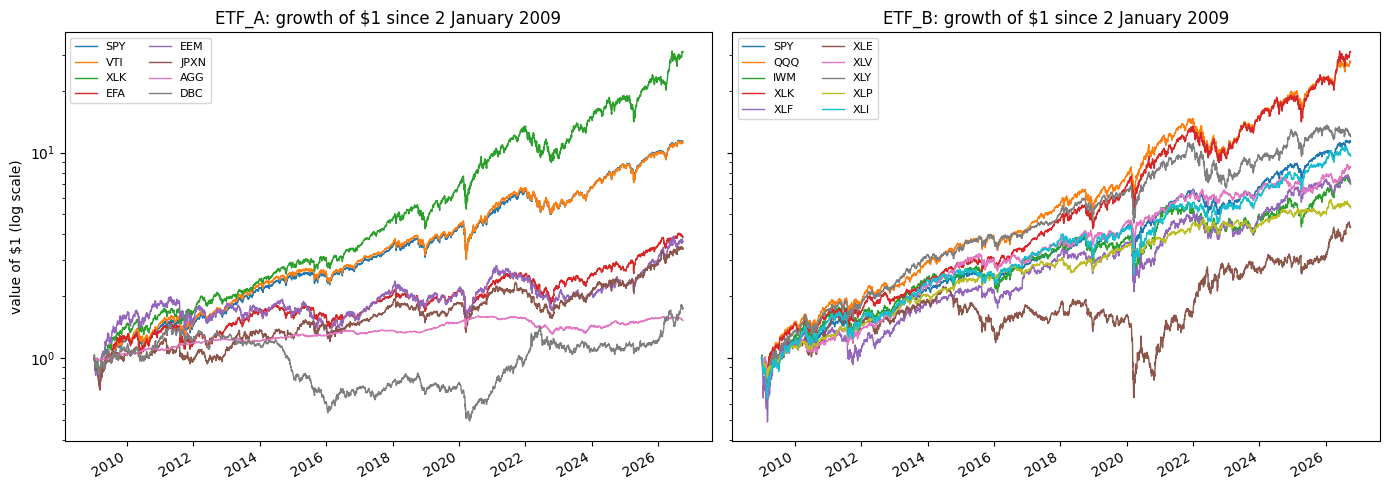

In [7]:
adj = clean.pivot(index="date", columns="ticker", values="adj_close")
growth = adj / adj.iloc[0]

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, (name, tickers) in zip(axes, [("ETF_A", config.ETF_A), ("ETF_B", config.ETF_B)]):
    growth[tickers].plot(ax=ax, logy=True, linewidth=1)
    ax.set_title(f"{name}: growth of $1 since 2 January 2009")
    ax.set_xlabel("")
    ax.legend(ncol=2, fontsize=8)
axes[0].set_ylabel("value of $1 (log scale)")
plt.tight_layout()
plt.show()

## 7. Cross-check with a second source (optional)

Compares monthly returns for SPY, AGG and JPXN with prices from Stooq. The check runs only if the files `Stooq SPY.csv`, `Stooq AGG.csv` or `Stooq JPXN.csv` have been placed in `data/raw`. Monthly returns that differ by more than 0.1 percentage point are flagged.

In [8]:
rows = []
for ticker in ["SPY", "AGG", "JPXN"]:
    path = DIRS["raw"] / f"Stooq {ticker}.csv"
    if path.exists():
        rows.append(cleaning.cross_check(clean, path, ticker))

if rows:
    display(pd.DataFrame(rows))
else:
    print("No Stooq files found, cross-check skipped.")

No Stooq files found, cross-check skipped.


## 8. Summary

Key figures for the process log and the Data Specification sheet. After the run, save the notebook (File > Save) so the outputs are kept.

In [9]:
print(f"Raw file:      {config.FILES['raw']}")
print(f"Checksum:      {info['md5']}")
print(f"Downloaded:    {info['downloaded_utc']}")
print(f"Rows:          {len(clean):,}")
print(f"Trading days:  {clean['date'].nunique():,}")
print(f"Month-ends:    {len(cleaning.month_end_dates(clean))}")
print(f"Checks:        {overall}, prices filled: {len(fill_log)}")

Raw file:      Raw Prices.csv
Checksum:      80113beee459649ee81eda775e0eee79
Downloaded:    2026-10-16T10:22:01+00:00
Rows:          71,408
Trading days:  4,463
Month-ends:    213
Checks:        WARN, prices filled: 0
